# Training comparison: with and without torch.compile

Train the baseline CNN twice for **50 epochs** from identical initial weights.


In [1]:
import copy
import gc
import random
import sys
import time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

project_root = Path.cwd()
if not (project_root / "src/cnn_project").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "src"))
from cnn_project.model import EuroSATModel
from cnn_project.data import create_data_loaders

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
EPOCHS = 45
SEED = 42
BATCH_SIZE = 64
NUM_WORKERS = 10
CHANNELS = (16, 32, 64, 128)
LR = 0.00633
GAMMA = 0.696
STEP_SIZE = 4


def reset_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def synchronize():
    if device.type == "cuda":
        torch.cuda.synchronize(device)


reset_seed(SEED)
initial_state = copy.deepcopy(EuroSATModel(channels=CHANNELS).state_dict())
print(f"Device: {device}; epochs per run: {EPOCHS}; batch size: {BATCH_SIZE}")


Device: cuda; epochs per run: 45; batch size: 64


In [2]:
def run_training(use_compile, train_loader, val_loader, epochs=EPOCHS,
                 compile_backend="inductor"):
    reset_seed(SEED)
    model = EuroSATModel(channels=CHANNELS).to(device)
    model.load_state_dict(initial_state)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    scheduler = torch.optim.lr_scheduler.StepLR(
        optimizer, step_size=STEP_SIZE, gamma=GAMMA
    )
    loss_fn = torch.nn.CrossEntropyLoss()
    history = []

    synchronize()
    run_start = time.perf_counter()
    if use_compile:
        # Compile once; the first train/validation calls trigger compilation.
        model.compile(backend=compile_backend,    options={"layout_optimization": False},
)

    for epoch in range(1, epochs + 1):
        synchronize()
        epoch_start = time.perf_counter()
        model.train()
        train_loss = torch.zeros((), device=device)
        train_correct = torch.zeros((), device=device, dtype=torch.long)
        train_total = 0
        learning_rate = optimizer.param_groups[0]["lr"]

        for images, labels in train_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            optimizer.zero_grad()
            predictions = model(images)
            loss = loss_fn(predictions, labels)
            loss.backward()
            optimizer.step()
            train_loss += loss.detach() * labels.numel()
            train_correct += (predictions.argmax(1) == labels).sum()
            train_total += labels.numel()

        model.eval()
        val_loss = torch.zeros((), device=device)
        val_correct = torch.zeros((), device=device, dtype=torch.long)
        val_total = 0
        with torch.inference_mode():
            for images, labels in val_loader:
                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)
                predictions = model(images)
                val_loss += loss_fn(predictions, labels) * labels.numel()
                val_correct += (predictions.argmax(1) == labels).sum()
                val_total += labels.numel()

        scheduler.step()
        synchronize()
        elapsed = time.perf_counter() - epoch_start
        row = {
            "epoch": epoch, "seconds": elapsed,
            "train_loss": train_loss.item() / train_total,
            "val_loss": val_loss.item() / val_total,
            "train_accuracy": train_correct.item() / train_total,
            "val_accuracy": val_correct.item() / val_total,
            "learning_rate": learning_rate,
        }
        history.append(row)
        label = "Compiled" if use_compile else "Uncompiled"
        print(f"{label} | epoch {epoch:02d}/{epochs} | {elapsed:.2f} s | "
              f"train {row['train_accuracy']:.2%} | val {row['val_accuracy']:.2%}")

    synchronize()
    total_seconds = time.perf_counter() - run_start
    # Return scalar results only; neither model nor weights are saved.
    return {"history": history, "total_seconds": total_seconds}


In [3]:
results = {}
for name, use_compile in (("Uncompiled", False), ("Compiled", True)):
    reset_seed(SEED)
    # Fresh generator and workers prevent one run from advancing the next run's
    # data-order and augmentation RNG state. The split itself is fixed in data.py.
    train_loader, val_loader, test_loader = create_data_loaders(
        batch_size=BATCH_SIZE,
        num_workers=NUM_WORKERS,
        generator=torch.Generator().manual_seed(SEED),
    )
    print(f"\nStarting {name.lower()} training")
    results[name] = run_training(use_compile, train_loader, val_loader)
    del train_loader, val_loader, test_loader
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()



Starting uncompiled training
Uncompiled | epoch 01/45 | 9.10 s | train 61.06% | val 67.07%
Uncompiled | epoch 02/45 | 2.29 s | train 72.48% | val 71.81%
Uncompiled | epoch 03/45 | 2.31 s | train 76.26% | val 74.70%
Uncompiled | epoch 04/45 | 2.19 s | train 79.41% | val 82.48%
Uncompiled | epoch 05/45 | 2.27 s | train 82.81% | val 82.37%
Uncompiled | epoch 06/45 | 2.34 s | train 84.19% | val 80.81%
Uncompiled | epoch 07/45 | 2.41 s | train 85.72% | val 84.74%
Uncompiled | epoch 08/45 | 2.36 s | train 86.23% | val 71.00%
Uncompiled | epoch 09/45 | 2.42 s | train 88.35% | val 88.07%
Uncompiled | epoch 10/45 | 2.30 s | train 88.80% | val 87.52%
Uncompiled | epoch 11/45 | 2.37 s | train 89.31% | val 81.07%
Uncompiled | epoch 12/45 | 2.50 s | train 89.60% | val 88.48%
Uncompiled | epoch 13/45 | 2.32 s | train 90.96% | val 81.37%
Uncompiled | epoch 14/45 | 2.45 s | train 91.27% | val 84.19%
Uncompiled | epoch 15/45 | 2.30 s | train 91.85% | val 93.22%
Uncompiled | epoch 16/45 | 2.44 s | trai

W1030 12:33:59.917000 219660 torch/_inductor/utils.py:1806] [0/1] Not enough SMs to use max_autotune_gemm mode


Compiled | epoch 01/45 | 14.31 s | train 60.57% | val 61.63%
Compiled | epoch 02/45 | 2.49 s | train 72.13% | val 74.59%
Compiled | epoch 03/45 | 2.36 s | train 76.71% | val 69.78%
Compiled | epoch 04/45 | 2.40 s | train 79.70% | val 70.37%
Compiled | epoch 05/45 | 2.58 s | train 82.77% | val 76.22%
Compiled | epoch 06/45 | 2.39 s | train 83.97% | val 84.93%
Compiled | epoch 07/45 | 2.52 s | train 85.56% | val 82.96%
Compiled | epoch 08/45 | 2.41 s | train 85.69% | val 71.85%
Compiled | epoch 09/45 | 2.55 s | train 88.46% | val 84.67%
Compiled | epoch 10/45 | 2.44 s | train 88.65% | val 74.81%
Compiled | epoch 11/45 | 2.48 s | train 88.97% | val 79.89%
Compiled | epoch 12/45 | 2.45 s | train 89.26% | val 91.26%
Compiled | epoch 13/45 | 2.37 s | train 90.74% | val 86.22%
Compiled | epoch 14/45 | 2.67 s | train 90.71% | val 92.52%
Compiled | epoch 15/45 | 2.57 s | train 91.60% | val 88.04%
Compiled | epoch 16/45 | 2.45 s | train 91.82% | val 89.78%
Compiled | epoch 17/45 | 2.39 s | train

| Run | Total time (s) | First epoch (s) | Mean epochs 2–50 (s) | Best validation accuracy | Final validation accuracy |
| --- | ---: | ---: | ---: | ---: | ---: |
| Uncompiled | 116.22 | 9.10 | 2.43 | 96.30% | 95.85% |
| Compiled | 125.47 | 14.31 | 2.51 | 95.70% | 95.52% |

Total-time speedup including compilation: 0.93×
Above 1× means compilation was faster overall.


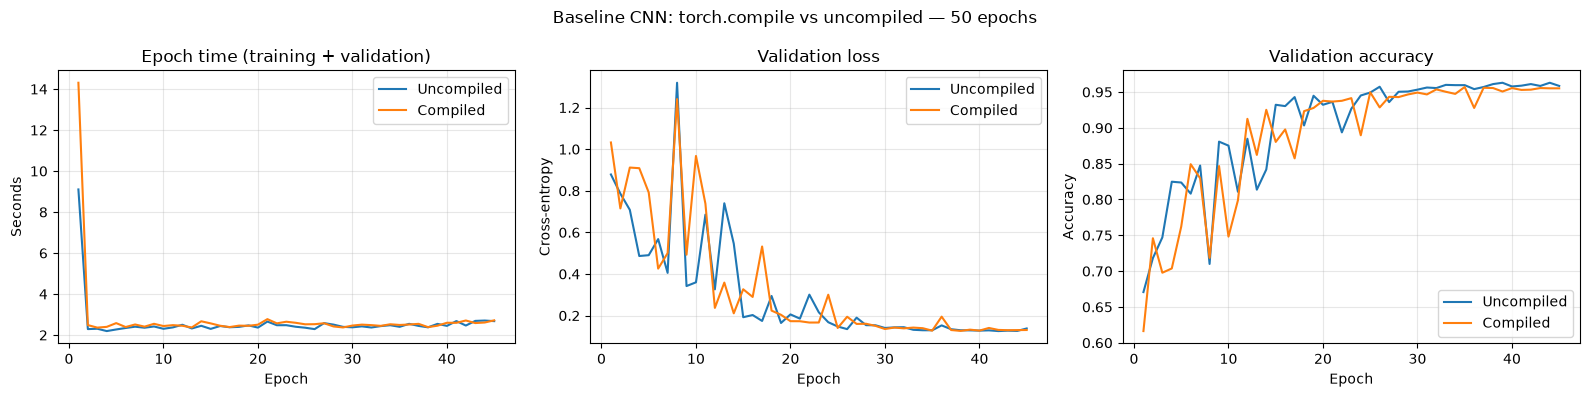

In [4]:
rows = ["| Run | Total time (s) | First epoch (s) | Mean epochs 2–50 (s) | Best validation accuracy | Final validation accuracy |",
        "| --- | ---: | ---: | ---: | ---: | ---: |"]
for name, result in results.items():
    history = result["history"]
    rows.append(
        f"| {name} | {result['total_seconds']:.2f} | {history[0]['seconds']:.2f} | "
        f"{np.mean([r['seconds'] for r in history[1:]]):.2f} | "
        f"{max(r['val_accuracy'] for r in history):.2%} | "
        f"{history[-1]['val_accuracy']:.2%} |"
    )
display(Markdown("\n".join(rows)))
speedup = results["Uncompiled"]["total_seconds"] / results["Compiled"]["total_seconds"]
print(f"Total-time speedup including compilation: {speedup:.2f}×")
print("Above 1× means compilation was faster overall.")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name, result in results.items():
    history = result["history"]
    epochs = [r["epoch"] for r in history]
    axes[0].plot(epochs, [r["seconds"] for r in history], label=name)
    axes[1].plot(epochs, [r["val_loss"] for r in history], label=name)
    axes[2].plot(epochs, [r["val_accuracy"] for r in history], label=name)
for ax, title, ylabel in zip(axes,
        ("Epoch time (training + validation)", "Validation loss", "Validation accuracy"),
        ("Seconds", "Cross-entropy", "Accuracy")):
    ax.set(title=title, xlabel="Epoch", ylabel=ylabel)
    ax.legend()
    ax.grid(alpha=0.3)
fig.suptitle("Baseline CNN: torch.compile vs uncompiled — 50 epochs")
fig.tight_layout()
plt.show()
